# Unified ADAF/SS/SE Accretion Model — Bayesian MCMC Analysis

This program uses a unified accretion model combining ADAF and SS/SE disk prescriptions to estimate black hole masses and dimensionless accretion rates from observed broad emission-line luminosities. A single transition at (\dot{m}=10^{-2}) separates the ADAF and SS/SE branches, while local Eddington capping determines the effective disk state. The MCMC analysis provides posterior distributions of the physical parameters and evaluates their compatibility with different accretion regimes.

In [1]:
# ============================================================================
# Imports and constants
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import root
from scipy.special import kv
import emcee
import corner
from IPython.display import display   

c = 2.99792458e10
G = 6.67430e-8
h = 6.62607015e-27
kB = 1.380649e-16
sigma_sb = 5.670374419e-5
Msun = 1.98847e33
eV_to_erg = 1.602176634e-12
hydrogen_ionization_energy = (
    13.6 * eV_to_erg
)
hydrogen_ionization_frequency = (
    hydrogen_ionization_energy / h
)

In [2]:
# ============================================================================
# Recombination coefficients : the Balmer lines are modeled using Case B recombination.
# ============================================================================

alpha_B_H = 2.59e-13

alpha_eff_balmer = {

    "Ha": 1.16e-13,
    "Hb": 3.07e-14,
    "Hg": 1.29e-14,
    "Hd": 6.79e-15,

    "Halpha": 1.16e-13,
    "Hbeta": 3.07e-14,
    "Hgamma": 1.29e-14,
    "Hdelta": 6.79e-15
}


# Rest wavelengths in Angstrom
balmer_wavelengths_angstrom = {

    "Ha": 6563.0,
    "Hb": 4861.0,
    "Hg": 4340.0,
    "Hd": 4102.0,

    "Halpha": 6563.0,
    "Hbeta": 4861.0,
    "Hgamma": 4340.0,
    "Hdelta": 4102.0
}

In [3]:
# ============================================================
# INPUT-DATA FUNCTIONS
# ============================================================

#funzione per cercare colonna nel dataframe con nomi alternativi
def find_column(
    df,
    possible_names,
    required=True
):

    for name in possible_names:

        if name in df.columns:

            return name


    if required:

        raise ValueError(
            f"None of the following columns were found: "
            f"{possible_names}"
        )


    return None


# funzione che legge il file delle transizioni e restituisce un dataframe con le informazioni sulle linee
def read_transitions(
    transition_file
):

    (
        line_names,
        ionization_energy,
        ionization_frequency
    ) = np.genfromtxt(
        transition_file,
        dtype=("U50", float, float),
        unpack=True
    )


    return pd.DataFrame({

        "line_name":
            line_names,

        "E_ion":
            ionization_energy,

        "nu_ion":
            ionization_frequency
    })


#funzione che estrae le linee osservate da un dataframe di righe, restituendo un dataframe con le informazioni sulle linee osservate
def extract_observed_lines(
    row,
    norm_columns,
    relative_error
):

    results = []


    for column in norm_columns:

        value = row[column]


        if (
            pd.isna(value)
            or value <= 0
        ):
            continue


        line_name = (
            column.replace(
                "_norm",
                ""
            )
        )


        uncertainty_column = (
            f"{line_name}_norm_unc"
        )


        # Convert normalized luminosities to erg/s
        line_luminosity = (
            value * 1e42
        )


        if (
            uncertainty_column in row.index
            and pd.notna(
                row[uncertainty_column]
            )
            and row[uncertainty_column] > 0
        ):

            sigma_luminosity = (
                row[uncertainty_column]
                * 1e42
            )

        else:

            sigma_luminosity = (
                relative_error
                * line_luminosity
            )


        results.append({

            "line_name":
                line_name,

            "norm_value":
                value,

            "L_line_obs":
                line_luminosity,

            "sigma_L":
                sigma_luminosity
        })


    return pd.DataFrame(
        results
    )


#funzione che prepara i dati del blazar, estraendo le linee osservate e le transizioni corrispondenti
def prepare_blazar_data(
    target_label,
    line_file,
    transition_file,
    relative_error,
    exclude_lines=None
):

    df_catalogue = pd.read_csv(
        line_file
    )


    df_transitions = read_transitions(
        transition_file
    )


    source_column = find_column(
        df_catalogue,
        [
            "label",
            "file_name",
            "name",
            "nome",
            "blazar"
        ]
    )


    norm_columns = [

        col
        for col in df_catalogue.columns
        if col.endswith("_norm")
    ]


    df_all_sources = (
        df_catalogue
        .rename(
            columns={
                source_column:
                    "label"
            }
        )
        .copy()
    )


    df_all_sources["label"] = (
        df_all_sources["label"]
        .astype(str)
        .str.strip()
    )


    target_label_clean = (
        str(target_label).strip()
    )


    df_match = df_all_sources[
        df_all_sources["label"]
        == target_label_clean
    ].copy()


    if df_match.empty:

        df_match = df_all_sources[
            df_all_sources["label"]
            .str.contains(
                target_label_clean,
                case=False,
                na=False
            )
        ].copy()


    if df_match.empty:

        print(
            "Available labels:"
        )

        print(
            df_all_sources[
                "label"
            ]
            .drop_duplicates()
            .sort_values()
            .tolist()
        )


        raise ValueError(
            f"No blazar found for "
            f"target_label='{target_label}'"
        )


    if len(df_match) > 1:

        print(
            "Multiple compatible sources found:"
        )

        print(
            df_match[
                "label"
            ].tolist()
        )

        print(
            "Using the first match."
        )


    selected_row = (
        df_match.iloc[0]
    )


    df_observed = (
        extract_observed_lines(
            selected_row,
            norm_columns,
            relative_error
        )
    )


    # --------------------------------------------------------
    # Exclude selected lines
    # --------------------------------------------------------

    if (
        exclude_lines is not None
        and len(exclude_lines) > 0
    ):

        exclude_lines = [

            str(line).strip()
            for line in exclude_lines
        ]


        df_observed = df_observed[
            ~df_observed[
                "line_name"
            ].isin(
                exclude_lines
            )
        ].copy()


        print(
            "Excluded emission lines:"
        )

        print(
            exclude_lines
        )


    df_observed = (
        df_observed.merge(

            df_transitions[
                [
                    "line_name",
                    "E_ion",
                    "nu_ion"
                ]
            ],

            on="line_name",
            how="left"
        )
    )


    df_observed[
        "sigma_L"
    ] = pd.to_numeric(
        df_observed[
            "sigma_L"
        ],
        errors="coerce"
    )


    df_observed.loc[
        (
            df_observed[
                "sigma_L"
            ].isna()
        )
        |
        (
            df_observed[
                "sigma_L"
            ] <= 0
        ),
        "sigma_L"
    ] = (
        relative_error
        * df_observed[
            "L_line_obs"
        ]
    )


    print(
        f"Selected blazar: "
        f"{selected_row['label']}"
    )

    print(
        f"Number of observed lines used: "
        f"{len(df_observed)}"
    )

    print(
        "Lines used:"
    )

    print(
        df_observed[
            "line_name"
        ].tolist()
    )


    return (
        df_all_sources,
        df_transitions,
        df_observed
    )

In [ ]:
# ============================================================
# SUPER-EDDINGTON / SHAKURA-SUNYAEV
# ============================================================

def build_se_spectrum(
    black_hole_mass_solar,
    eddington_accretion_rate,
    cfg
):
    """
    Compute the spectrum of the radiatively efficient disk branch.

    The underlying Shakura-Sunyaev local flux is

        F_SS(R)

    and the adopted prescription is

        F(R) = min[F_SS(R), F_Edd(R)].

    Therefore:

        F_SS <= F_Edd  -> standard SS behaviour
        F_SS >  F_Edd  -> local Eddington capping

    No additional SS/SE switch is imposed.
    """

    black_hole_mass = black_hole_mass_solar * Msun

    radiative_efficiency = cfg["eta"]
    number_radial_points = cfg["Nr"]
    number_frequency_points = cfg["Nnu_disk"]
    minimum_frequency = cfg["nu_min_disk"]
    maximum_frequency = cfg["nu_max_disk"]

    eddington_luminosity = 1.3e38 * black_hole_mass_solar

    ss_input_disk_luminosity = (            
        eddington_accretion_rate * eddington_luminosity  
    )

    mass_accretion_rate = (
        ss_input_disk_luminosity / (radiative_efficiency * c**2)
    )

    schwarzschild_radius = 2 * G * black_hole_mass / c**2

    inner_radius = 3 * schwarzschild_radius
    outer_radius = 3000 * schwarzschild_radius

    radius_grid = np.logspace(
        np.log10(inner_radius),
        np.log10(outer_radius),
        number_radial_points
    )

    # --------------------------------------------------------
    # SS inner-boundary factor
    # --------------------------------------------------------

    boundary_factor = 1.0 - np.sqrt(inner_radius / radius_grid)
    boundary_factor = np.clip(boundary_factor, 0.0, None)

    # --------------------------------------------------------
    # Standard SS local flux
    # --------------------------------------------------------

    flux_ss = (
        (3 * G * black_hole_mass * mass_accretion_rate)
        / (8 * np.pi * radius_grid**3)
        * boundary_factor
    )

    # --------------------------------------------------------
    # Local Eddington flux
    # --------------------------------------------------------

    flux_eddington = (
        eddington_luminosity / (4 * np.pi * radius_grid**2)
    )

    # --------------------------------------------------------
    # Unified SS/SE prescription
    #
    # If F_SS < F_Edd -> unchanged SS flux
    #
    # If F_SS > F_Edd -> Eddington cap
    # --------------------------------------------------------

    flux_disk = np.minimum(flux_ss, flux_eddington)

    eddington_limited_mask = flux_ss > flux_eddington

    has_eddington_limited_region = bool(
        np.any(eddington_limited_mask)
    )

    # --------------------------------------------------------
    # Effective temperature profile
    # --------------------------------------------------------

    temperature_profile = (flux_disk / sigma_sb)**0.25

    # --------------------------------------------------------
    # Frequency grid
    # --------------------------------------------------------

    frequency_grid = np.logspace(
        np.log10(minimum_frequency),
        np.log10(maximum_frequency),
        number_frequency_points
    )

    # --------------------------------------------------------
    # Planck function
    # --------------------------------------------------------

    planck_function = np.zeros(
        (number_frequency_points, number_radial_points)
    )

    for j in range(number_radial_points):

        if temperature_profile[j] <= 0:
            continue

        x = (
            h * frequency_grid
            / (kB * temperature_profile[j])
        )

        x = np.clip(x, 1e-12, 700.0)    

        planck_function[:, j] = (
            (2 * h * frequency_grid**3 / c**2)
            / np.expm1(x)     #expm1(x) = exp(x) - 1, more accurate for small x
        )

    # --------------------------------------------------------
    # Integrate over radius
    # --------------------------------------------------------

    integrand = radius_grid[None, :] * planck_function

    integrated_intensity = np.trapezoid(
        integrand, radius_grid, axis=1
    )

    luminosity_spectrum = 4 * np.pi**2 * integrated_intensity

    spectral_energy_distribution = (
        frequency_grid * luminosity_spectrum
    )

    # --------------------------------------------------------
    # Identify the effective state 
    # --------------------------------------------------------

    if has_eddington_limited_region:
        effective_disk_state = "SE-capped"
    else:
        effective_disk_state = "SS-like"

    model_info = {
        # This is the MCMC branch
        "regime": "SE",
        # This describes whether capping is actually active
        "effective_disk_state": effective_disk_state,
        "has_eddington_limited_region": has_eddington_limited_region
    }

    return (
        frequency_grid,
        luminosity_spectrum,
        spectral_energy_distribution,
        model_info
    )


In [ ]:
# ============================================================
# ADAF 
# ============================================================

def bessel_k(
    order,
    argument
):

    return kv(
        order,
        argument
    )



def adaf_thermal_function(
    theta_e
):

    bessel_value = bessel_k(
        2,
        1.0 / theta_e
    )


    if (
        not np.isfinite(
            bessel_value
        )
        or bessel_value <= 0
    ):

        return np.nan


    return (

        (1.0 / bessel_value)

        * (
            2.0
            + 2.0 * theta_e
            + 1.0 / theta_e
        )

        * np.exp(
            -1.0 / theta_e
        )
    )



def adaf_temperature_equations(
    variables,
    accretion_rate,
    black_hole_mass,
    beta,
    cfg
):

    if not np.all(
        np.isfinite(
            variables
        )
    ):

        return [
            1e99,
            1e99,
            1e99
        ]


    if (
        accretion_rate <= 0
        or black_hole_mass <= 0
        or beta <= 0
        or beta >= 1
    ):

        return [
            1e99,
            1e99,
            1e99
        ]


    if np.any(
        np.abs(
            variables
        )
        > 1e3
    ):

        return [
            1e99,
            1e99,
            1e99
        ]


    alpha = (
        cfg["alfa"]
    )

    inner_radius = (
        cfg["rmin"]
    )

    outer_radius = (
        cfg["rmax"]
    )

    electron_heating_fraction = (
        cfg["delta"]
    )

    c1 = (
        cfg["c1"]
    )

    c3 = (
        cfg["c3"]
    )

    temperature_normalization = (
        cfg["tnorm"]
    )


    # Squared variables guarantee positive quantities
    advection_fraction = (
        variables[2]**2
    )

    synchrotron_parameter = (
        1e3
        * variables[1]**2
    )

    theta_e = (
        variables[0]**2
    )


    if (
        advection_fraction <= 0
        or synchrotron_parameter <= 0
        or theta_e <= 1e-12
    ):

        return [
            1e99,
            1e99,
            1e99
        ]


    thermal_factor = (
        adaf_thermal_function(
            theta_e
        )
    )


    if not np.isfinite(
        thermal_factor
    ):

        return [
            1e99,
            1e99,
            1e99
        ]


    synchrotron_scale_1 = (

        1.42e9

        * alpha**(-0.5)

        * np.sqrt(
            1 - beta
        )

        * c1**(-0.5)

        * c3**0.5
    )


    synchrotron_scale_2 = (
        1.19e-13
        * synchrotron_parameter
    )


    # --------------------------------------------------------
    # Heating
    # --------------------------------------------------------

    ion_heating = (

        1.2e4

        * thermal_factor

        * alpha**(-2)

        * c1**(-2)

        * c3

        * beta

        * black_hole_mass

        * accretion_rate**2

        / inner_radius
    )


    electron_heating = (

        electron_heating_fraction

        * 9.39e4

        * (
            (1 - beta)
            / advection_fraction
        )

        * c3

        * black_hole_mass

        * accretion_rate

        / inner_radius
    )


    total_heating = (
        ion_heating
        + electron_heating
    )


    # --------------------------------------------------------
    # Synchrotron
    # --------------------------------------------------------

    peak_synchrotron_frequency = (

        synchrotron_scale_1

        * synchrotron_scale_2

        * black_hole_mass**(-0.5)

        * accretion_rate**0.5

        * (
            theta_e
            / temperature_normalization
        )**2

        * inner_radius**(-5/4)
    )


    if (
        not np.isfinite(
            peak_synchrotron_frequency
        )
        or peak_synchrotron_frequency <= 0
    ):

        return [
            1e99,
            1e99,
            1e99
        ]


    synchrotron_power = (

        53.0

        * (
            synchrotron_parameter
            / 1000.0
        )**3

        * (
            theta_e
            /
            (
                1e9
                * temperature_normalization
            )
        )**7

        * black_hole_mass**0.5

        * accretion_rate**1.5
    )


    # --------------------------------------------------------
    # Compton
    # --------------------------------------------------------

    compton_amplification = (
        1
        + 4 * theta_e
        + 16 * theta_e**2
    )


    optical_depth = (
        23.87
        * accretion_rate
    )


    if (
        optical_depth <= 0
        or compton_amplification <= 1
    ):

        return [
            1e99,
            1e99,
            1e99
        ]


    compton_slope = (

        -np.log(
            optical_depth
        )

        /

        np.log(
            compton_amplification
        )
    )


    try:

        compton_base = (

            6.2e7

            * (
                theta_e
                /
                (
                    1e9
                    * temperature_normalization
                )
            )

            /

            (
                peak_synchrotron_frequency
                * 1e-12
            )
        )


        if (
            compton_base <= 0
            or not np.isfinite(
                compton_base
            )
        ):

            return [
                1e99,
                1e99,
                1e99
            ]


        compton_factor = (

            compton_base**(
                1 - compton_slope
            )

            - 1
        )


        compton_power = (

            (
                synchrotron_power
                / 0.71
            )

            /

            (
                1
                - compton_slope
            )

            * compton_factor
        )


    except Exception:

        return [
            1e99,
            1e99,
            1e99
        ]


    # --------------------------------------------------------
    # Bremsstrahlung
    # --------------------------------------------------------

    if theta_e < 1:

        bremsstrahlung_factor = (

            4

            * np.sqrt(
                2
                * theta_e
                / np.pi**3
            )

            * (
                1
                + 1.781
                * theta_e**1.34
            )
        )

    else:

        bremsstrahlung_factor = (

            (
                9
                * theta_e
                /
                (
                    2
                    * np.pi
                )
            )

            * (
                np.log(
                    1.123
                    * theta_e
                    + 0.48
                )
                + 1.5
            )
        )


    bremsstrahlung_power = (

        4.78

        * alpha**(-2)

        * c1**(-2)

        * np.log(
            outer_radius
            / inner_radius
        )

        * bremsstrahlung_factor

        * black_hole_mass

        * accretion_rate**2
    )


    # --------------------------------------------------------
    # Residual equations
    # --------------------------------------------------------

    residual_energy = (

        total_heating

        - synchrotron_power

        - compton_power

        - bremsstrahlung_power
    )


    residual_advection = (

        (
            1
            - advection_fraction
        )

        * 9.39e4

        * (
            (1 - beta)
            / advection_fraction
        )

        * c3

        * black_hole_mass

        * accretion_rate

        / inner_radius

        - total_heating
    )


    bessel_value = bessel_k(
        2,
        1 / theta_e
    )


    logarithm_argument = (
        theta_e**3
        * bessel_value
    )


    if (
        not np.isfinite(
            logarithm_argument
        )
        or logarithm_argument <= 0
    ):

        return [
            1e99,
            1e99,
            1e99
        ]


    transformed_synchrotron_parameter = (
        synchrotron_parameter**(
            1 / 3
        )
    )


    residual_synchrotron = (

        transformed_synchrotron_parameter

        + 1.852
        * np.log(
            transformed_synchrotron_parameter
        )

        - 10.36

        - 0.26
        * np.log(
            black_hole_mass
            * accretion_rate
        )

        + 0.26
        * np.log(
            logarithm_argument
        )
    )


    residuals = np.array(
        [
            residual_energy,
            residual_synchrotron,
            residual_advection
        ],
        dtype=float
    )


    if not np.all(
        np.isfinite(
            residuals
        )
    ):

        return [
            1e99,
            1e99,
            1e99
        ]


    return residuals.tolist()



def build_adaf_spectrum_from_solution(
    electron_temperature,
    advection_fraction,
    synchrotron_parameter,
    black_hole_mass,
    accretion_rate,
    beta,
    cfg
):

    alpha = (
        cfg["alfa"]
    )

    inner_radius = (
        cfg["rmin"]
    )

    outer_radius = (
        cfg["rmax"]
    )

    c1 = (
        cfg["c1"]
    )

    c3 = (
        cfg["c3"]
    )

    temperature_normalization = (
        cfg["tnorm"]
    )


    minimum_frequency = (
        cfg["nu_min_adaf"]
    )

    maximum_frequency = (
        cfg["nu_max_adaf"]
    )

    number_frequency_points = (
        cfg["Nnu_adaf"]
    )


    log_frequency_grid = np.linspace(
        np.log10(
            minimum_frequency
        ),
        np.log10(
            maximum_frequency
        ),
        number_frequency_points
    )


    frequency_grid = (
        10**log_frequency_grid
    )


    theta_e = (
        temperature_normalization
        * electron_temperature
    )


    if (
        electron_temperature <= 0
        or theta_e <= 0
    ):

        raise RuntimeError(
            "Invalid ADAF temperature"
        )


    synchrotron_scale_1 = (

        1.42e9

        * alpha**(-0.5)

        * np.sqrt(
            1 - beta
        )

        * c1**(-0.5)

        * c3**0.5
    )


    synchrotron_scale_2 = (
        1.19e-13
        * synchrotron_parameter
    )


    synchrotron_scale_3 = ( 
        1.05e-24
    )


    compton_amplification = (
        1
        + 4 * theta_e
        + 16 * theta_e**2
    )


    optical_depth = (
        23.87
        * accretion_rate
    )


    if (
        optical_depth <= 0
        or compton_amplification <= 1
    ):

        raise RuntimeError(
            "Invalid ADAF Compton parameters"
        )


    compton_slope = (

        -np.log(
            optical_depth
        )

        /

        np.log(
            compton_amplification
        )
    )


    log_peak_synchrotron_frequency = np.log10(

        synchrotron_scale_1

        * synchrotron_scale_2

        * black_hole_mass**(-0.5)

        * accretion_rate**0.5

        * electron_temperature**2

        * inner_radius**(-5/4)
    )


    log_maximum_compton_frequency = (

        np.log10(
            electron_temperature
        )

        + 10.796
    )


    log_synchrotron_peak_luminosity = (

        3
        * np.log10(
            synchrotron_scale_1
            * synchrotron_scale_2
        )

        + np.log10(
            synchrotron_scale_3
        )

        - (7 / 4)
        * np.log10(
            inner_radius
        )

        + np.log10(
            black_hole_mass**0.5
            * accretion_rate**1.5
        )

        + 7
        * np.log10(
            electron_temperature
        )
    )


    log_synchrotron_luminosity = np.zeros(
        number_frequency_points
    )


    log_compton_luminosity = np.zeros(
        number_frequency_points
    )


    log_bremsstrahlung_luminosity = np.zeros(
        number_frequency_points
    )


    if theta_e < 1:

        bremsstrahlung_factor = (

            4

            * np.sqrt(
                2
                * theta_e
                / np.pi**3
            )

            * (
                1
                + 1.781
                * theta_e**1.34
            )
        )

    else:

        bremsstrahlung_factor = (

            (
                9
                * theta_e
                /
                (
                    2
                    * np.pi
                )
            )

            * (
                np.log(
                    1.123
                    * theta_e
                    + 0.48
                )

                + 1.5
            )
        )


    for i in range(
        number_frequency_points
    ):

        # ----------------------------------------------------
        # Synchrotron
        # ----------------------------------------------------

        if (
            log_frequency_grid[i]
            <
            log_peak_synchrotron_frequency
        ):

            log_synchrotron_luminosity[i] = (

                np.log10(
                    synchrotron_scale_3
                )

                + (8 / 5)
                * np.log10(
                    synchrotron_scale_1
                    * synchrotron_scale_2
                )

                + np.log10(
                    black_hole_mass**(6 / 5)
                    * accretion_rate**(4 / 5)
                )

                + (21 / 5)
                * np.log10(
                    electron_temperature
                )

                + (2 / 5)
                * log_frequency_grid[i]
            )


        # ----------------------------------------------------
        # Compton
        # ----------------------------------------------------

        if (
            log_frequency_grid[i]
            >
            log_peak_synchrotron_frequency
        ):

            compton_base = (

                log_synchrotron_peak_luminosity

                + (
                    compton_slope
                    - 1
                )
                * log_peak_synchrotron_frequency

                - compton_slope
                * log_frequency_grid[i]
            )


            compton_cutoff = (

                -(
                    10**(
                        log_frequency_grid[i]
                        -
                        log_maximum_compton_frequency
                    )
                )

                / np.log(10)
            )


            log_compton_luminosity[i] = (
                compton_base
                + compton_cutoff
            )


        # ----------------------------------------------------
        # Bremsstrahlung
        # ----------------------------------------------------

        bremsstrahlung_base = (

            24.36

            - 2
            * np.log10(
                alpha
                * c1
            )

            + np.log10(
                np.log(
                    outer_radius
                    / inner_radius
                )
                * bremsstrahlung_factor
            )

            - np.log10(
                electron_temperature
            )

            + np.log10(
                black_hole_mass
                * accretion_rate**2
            )
        )


        bremsstrahlung_cutoff = (

            -(
                4.8e-11
                * frequency_grid[i]
                / electron_temperature
            )

            / np.log(10)
        )


        log_bremsstrahlung_luminosity[i] = (

            bremsstrahlung_base
            + bremsstrahlung_cutoff
        )


    total_flux = (

        10**log_synchrotron_luminosity

        + 10**log_compton_luminosity

        + 10**log_bremsstrahlung_luminosity
    )


    if (
        not np.all(
            np.isfinite(
                total_flux
            )
        )
        or np.any(
            total_flux < 0
        )
    ):

        raise RuntimeError(
            "Invalid ADAF flux"
        )


    log_spectral_energy_distribution = (

        log_frequency_grid

        + np.log10(
            total_flux
        )
    )


    return (
        log_frequency_grid,
        log_spectral_energy_distribution
    )



def compute_adaf_spectral_data(
    black_hole_mass,
    accretion_rate,
    beta,
    cfg,
    verbose=False
):

    if verbose:

        print(
            f"ADAF -> "
            f"m={black_hole_mass:.3e}, "
            f"mdot={accretion_rate:.3e}, "
            f"beta={beta}"
        )


    initial_solution = (
        cfg["root_y0"]
    )


    solution = root(

        adaf_temperature_equations,

        initial_solution,

        args=(
            accretion_rate,
            black_hole_mass,
            beta,
            cfg
        ),

        tol=cfg[
            "root_tol"
        ]
    )


    if not solution.success:

        raise RuntimeError(
            f"Root did not converge for "
            f"m={black_hole_mass:.3e}, "
            f"mdot={accretion_rate:.3e}"
        )


    solver_variables = (
        solution.x
    )


    theta_e = (
        solver_variables[0]**2
    )


    electron_temperature = (
        theta_e
        / cfg["tnorm"]
    )


    synchrotron_parameter = (

        1e3
        * solver_variables[1]**2
    )


    advection_fraction = (
        solver_variables[2]**2
    )


    (
        log_frequency_grid,
        log_spectral_energy_distribution
    ) = build_adaf_spectrum_from_solution(

        electron_temperature,
        advection_fraction,
        synchrotron_parameter,
        black_hole_mass,
        accretion_rate,
        beta,
        cfg
    )


    frequency_grid = (
        10**log_frequency_grid
    )


    log_luminosity_spectrum = (

        log_spectral_energy_distribution

        - log_frequency_grid
    )


    luminosity_spectrum = (
        10**log_luminosity_spectrum
    )


    spectral_energy_distribution = (

        frequency_grid
        * luminosity_spectrum
    )


    model_info = {

        "regime":
            "ADAF",

        "effective_disk_state":
            "ADAF",

        "black_hole_mass":
            black_hole_mass,

        "accretion_rate":
            accretion_rate,

        "beta":
            beta,

        "electron_temperature":
            electron_temperature,

        "synchrotron_parameter":
            synchrotron_parameter,

        "advection_fraction":
            advection_fraction,

        "root_success":
            solution.success,

        "has_eddington_limited_region":
            False
    }


    return (
        frequency_grid,
        luminosity_spectrum,
        spectral_energy_distribution,
        model_info
    )



def build_adaf_spectrum(
    black_hole_mass_solar,
    eddington_accretion_rate,
    cfg
):

    beta = (
        cfg["beta_adaf"]
    )


    (
        frequency_grid,
        luminosity_spectrum,
        spectral_energy_distribution,
        model_info
    ) = compute_adaf_spectral_data(

        black_hole_mass=
            black_hole_mass_solar,

        accretion_rate=
            eddington_accretion_rate,

        beta=
            beta,

        cfg=
            cfg,

        verbose=
            False
    )


    valid_mask = (

        np.isfinite(
            frequency_grid
        )

        & np.isfinite(
            luminosity_spectrum
        )

        & np.isfinite(
            spectral_energy_distribution
        )

        & (
            frequency_grid > 0
        )

        & (
            luminosity_spectrum >= 0
        )
    )


    frequency_grid = (
        frequency_grid[
            valid_mask
        ]
    )


    luminosity_spectrum = (
        luminosity_spectrum[
            valid_mask
        ]
    )


    spectral_energy_distribution = (
        spectral_energy_distribution[
            valid_mask
        ]
    )


    if len(
        frequency_grid
    ) < 2:

        raise RuntimeError(
            "Invalid ADAF spectrum after filtering"
        )


    sorting_index = (
        np.argsort(
            frequency_grid
        )
    )


    return (

        frequency_grid[
            sorting_index
        ],

        luminosity_spectrum[
            sorting_index
        ],

        spectral_energy_distribution[
            sorting_index
        ],

        model_info
    )

In [6]:
# ============================================================
# PHOTOIONIZATION / EMISSION LINES
# ============================================================

def compute_line_driving_quantities(
    frequency_grid,
    luminosity_spectrum,
    df_transitions,
    maximum_ionizing_frequency
):
    """
    Compute the ionizing radiation available to produce
    each emission line from the accretion spectrum.
    """

    results = []

    # --------------------------------------------------------
    # Hydrogen-ionizing photon rate
    # --------------------------------------------------------

    # Select frequencies above the hydrogen ionization threshold
    hydrogen_mask = (
        (frequency_grid >= hydrogen_ionization_frequency)
        & (frequency_grid <= maximum_ionizing_frequency)
    )

    # Integrate the number of ionizing photons per second
    if np.sum(hydrogen_mask) < 2:
        Q_H = 0.0
    else:
        Q_H = np.trapezoid(
            luminosity_spectrum[hydrogen_mask]
            / (h * frequency_grid[hydrogen_mask]),
            frequency_grid[hydrogen_mask]
        )

    # --------------------------------------------------------
    # Compute the emission-line luminosities
    # --------------------------------------------------------

    for _, row in df_transitions.iterrows():

        line_name = str(row["line_name"]).strip()
        ionizing_frequency = row["nu_ion"]
        ionization_energy = row["E_ion"]

        # ====================================================
        # BALMER LINES: Case B recombination
        # ====================================================

        if line_name in alpha_eff_balmer:

            # Rest-frame frequency of the emission line
            wavelength_cm = (
                balmer_wavelengths_angstrom[line_name] * 1e-8
            )
            line_frequency = c / wavelength_cm

            # Effective recombination coefficient
            effective_recombination_coefficient = (
                alpha_eff_balmer[line_name]
            )

            # Fraction of recombinations producing this line
            recombination_ratio = (
                effective_recombination_coefficient / alpha_B_H
            )

            # Expected line luminosity before applying the BLR covering factor
            line_luminosity_without_cf = (
                h * line_frequency * recombination_ratio * Q_H
            )

            results.append({
                "line_name": line_name,
                "E_ion": 13.6,
                "nu_ion": hydrogen_ionization_frequency,
                "Q_H": Q_H,
                "L_ion": np.nan,
                "nu_line": line_frequency,
                "alpha_eff": effective_recombination_coefficient,
                "alpha_B": alpha_B_H,
                "alpha_ratio": recombination_ratio,
                "L_line_without_cf": line_luminosity_without_cf,
                "line_model": "Balmer_CaseB"
            })

        # ====================================================
        # NON-BALMER LINES: Ionizing luminosity
        # ====================================================

        else:

            # Check whether the ionization threshold is valid
            if (
                not np.isfinite(ionizing_frequency)
                or ionizing_frequency >= maximum_ionizing_frequency
            ):
                ionizing_luminosity = 0.0

            else:

                # Select frequencies above the ionization threshold
                valid_frequency_range = (
                    (frequency_grid >= ionizing_frequency)
                    & (frequency_grid <= maximum_ionizing_frequency)
                )

                # Integrate the ionizing luminosity
                if np.sum(valid_frequency_range) < 2:  
                    ionizing_luminosity = 0.0
                else:
                    ionizing_luminosity = np.trapezoid(
                        luminosity_spectrum[valid_frequency_range],
                        frequency_grid[valid_frequency_range]
                    )

            results.append({
                "line_name": line_name,
                "E_ion": ionization_energy,
                "nu_ion": ionizing_frequency,
                "Q_H": np.nan,
                "L_ion": ionizing_luminosity,
                "nu_line": np.nan,
                "alpha_eff": np.nan,
                "alpha_B": np.nan,
                "alpha_ratio": np.nan,
                "L_line_without_cf": ionizing_luminosity,
                "line_model": "Cf_times_Lion"
            })

    return pd.DataFrame(results)


In [7]:
# ============================================================
# ACCRETION-REGIME SWITCH
# ============================================================

def regime_from_logmdot(
    log_accretion_rate,
    cfg
):
    """
    Single accretion-regime switch:

        logmdot < -2  -> ADAF
        logmdot >= -2 -> SE branch

    The SE branch automatically reproduces the standard SS
    solution if F_SS never exceeds F_Edd.
    """

    if (log_accretion_rate <cfg["logmdot_switch_adaf_se"]):
        return "ADAF"

    return "SE"

In [8]:
# ============================================================
# UNIFIED CONTINUUM MODEL
# ============================================================

def build_unified_spectrum(
    log_black_hole_mass,
    log_accretion_rate,
    cfg
):
    """
    Build the accretion spectrum using the ADAF or SS/SE model.
    """

    # Convert logarithmic parameters to linear values
    black_hole_mass = 10**log_black_hole_mass
    accretion_rate = 10**log_accretion_rate

    # Select the accretion branch
    regime = regime_from_logmdot(log_accretion_rate, cfg)

    # --------------------------------------------------------
    # ADAF branch
    # --------------------------------------------------------

    if regime == "ADAF":

        (
            frequency_grid,
            luminosity_spectrum,
            spectral_energy_distribution,
            model_info
        ) = build_adaf_spectrum(
            black_hole_mass_solar=black_hole_mass,
            eddington_accretion_rate=accretion_rate,
            cfg=cfg
        )

    # --------------------------------------------------------
    # SS/SE branch
    # --------------------------------------------------------

    else:

        (
            frequency_grid,
            luminosity_spectrum,
            spectral_energy_distribution,
            model_info
        ) = build_se_spectrum(
            black_hole_mass_solar=black_hole_mass,
            eddington_accretion_rate=accretion_rate,
            cfg=cfg
        )

    # Store the selected accretion branch
    model_info["regime"] = regime

    return (
        frequency_grid,
        luminosity_spectrum,
        spectral_energy_distribution,
        model_info
    )

In [9]:
# ============================================================
# LINE PREDICTION
# ============================================================

def predict_lines_from_unified_model(
    log_black_hole_mass,
    log_accretion_rate,
    df_transitions,
    cfg
):
    """
    Predict the emission-line luminosities from the
    unified accretion model.
    """

    # Compute the accretion continuum
    (
        frequency_grid,
        luminosity_spectrum,
        spectral_energy_distribution,
        model_info
    ) = build_unified_spectrum(
        log_black_hole_mass=log_black_hole_mass,
        log_accretion_rate=log_accretion_rate,
        cfg=cfg
    )

    # Compute the luminosity available for each emission line
    df_line_model = compute_line_driving_quantities(
        frequency_grid,
        luminosity_spectrum,
        df_transitions,
        maximum_ionizing_frequency=cfg["nu_max_ion"]
    )

    # --------------------------------------------------------
    # BLR covering factor
    # --------------------------------------------------------

    # Select the covering factor for the accretion branch
    if model_info["regime"] == "ADAF":
        covering_factor = cfg["cf_blr_adaf"]
    else:
        covering_factor = cfg["cf_blr_se"]

    # Compute the predicted line luminosities
    df_line_model["L_line_mod"] = (
        covering_factor * df_line_model["L_line_without_cf"]
    )

    # Store the accretion branch and effective disk state
    df_line_model["regime"] = model_info["regime"]

    df_line_model["effective_disk_state"] = model_info.get(
        "effective_disk_state",
        model_info["regime"]
    )

    return df_line_model, model_info["regime"]

In [10]:
# ============================================================
# PRIORS
# ============================================================

def log_gaussian_prior(value, mean, standard_deviation):
    """
    Compute the log-probability density of a Gaussian prior.
    """

    return (
        -0.5 * ((value - mean) / standard_deviation)**2
        - np.log(standard_deviation * np.sqrt(2 * np.pi))
    )


def log_prior(parameter_vector, cfg):
    """
    Compute the total log-prior for the MCMC parameters.
    """

    log_black_hole_mass, log_accretion_rate = parameter_vector

    # Gaussian prior on the logarithmic black hole mass
    log_prior_mass = log_gaussian_prior(
        log_black_hole_mass,
        cfg["prior_logm_mu"],
        cfg["prior_logm_sigma"]
    )

    # Gaussian prior on the logarithmic accretion rate
    log_prior_accretion_rate = log_gaussian_prior(
        log_accretion_rate,
        cfg["prior_logmdot_mu"],
        cfg["prior_logmdot_sigma"]
    )

    # Sum the two independent log-priors
    return log_prior_mass + log_prior_accretion_rate

In [11]:
# ============================================================
# LIKELIHOOD
# ============================================================

def log_likelihood(
    parameter_vector,
    df_observed,
    df_transitions,
    cfg
):
    """
    Compute the Gaussian log-likelihood by comparing
    predicted and observed emission-line luminosities.
    """

    log_black_hole_mass, log_accretion_rate = parameter_vector

    # Compute the predicted emission-line luminosities
    try:
        df_model, regime = predict_lines_from_unified_model(
            log_black_hole_mass=log_black_hole_mass,
            log_accretion_rate=log_accretion_rate,
            df_transitions=df_transitions,
            cfg=cfg
        )

    except Exception:
        return -np.inf

    # Reject invalid model predictions
    if df_model is None or df_model.empty:
        return -np.inf

    if not np.all(np.isfinite(df_model["L_line_mod"].values)):
        return -np.inf

    # Match observed and predicted emission lines
    df_comparison = df_observed.merge(
        df_model[["line_name", "L_line_mod"]],
        on="line_name",
        how="inner"
    )

    # Keep only lines with valid luminosities and uncertainties
    df_comparison = df_comparison[
        df_comparison["L_line_obs"].notna()
        & df_comparison["sigma_L"].notna()
        & df_comparison["L_line_mod"].notna()
        & np.isfinite(df_comparison["L_line_mod"])
        & (df_comparison["L_line_mod"] >= 0)
        & (df_comparison["sigma_L"] > 0)
    ].copy()

    if len(df_comparison) == 0:
        return -np.inf

    # Difference between observed and predicted luminosities
    residuals = (
        df_comparison["L_line_obs"].values
        - df_comparison["L_line_mod"].values
    )

    observational_uncertainties = df_comparison["sigma_L"].values

    # Check that residuals and uncertainties are finite
    if (
        not np.all(np.isfinite(residuals))
        or not np.all(np.isfinite(observational_uncertainties))
    ):
        return -np.inf

    # Gaussian log-likelihood
    return -0.5 * np.sum(
        (residuals / observational_uncertainties)**2
        + np.log(2 * np.pi * observational_uncertainties**2)
    )

In [12]:
# ============================================================
# POSTERIOR
# ============================================================

def log_posterior(
    parameter_vector,
    df_observed,
    df_transitions,
    cfg
):
    """
    Compute the log-posterior probability for the MCMC.
    """

    # Compute the log-prior
    prior_value = log_prior(parameter_vector, cfg)

    if not np.isfinite(prior_value):
        return -np.inf

    # Compute the log-likelihood
    likelihood_value = log_likelihood(
        parameter_vector,
        df_observed,
        df_transitions,
        cfg
    )

    if not np.isfinite(likelihood_value):
        return -np.inf

    # Combine prior and likelihood
    return prior_value + likelihood_value

In [13]:
# ============================================================
# WALKER INITIALIZATION
# ============================================================

def initialize_walkers(cfg):
    """
    Generate the initial positions of the MCMC walkers.
    """

    # Set the random seed for reproducibility
    random_generator = np.random.default_rng(cfg["random_seed"])

    initial_positions = []

    # Generate starting positions for all walkers
    while len(initial_positions) < cfg["nwalkers"]:

        trial_position = np.array([
            random_generator.normal(
                cfg["guess_logm"], cfg["spread_logm"]
            ),
            random_generator.normal(
                cfg["guess_logmdot"], cfg["spread_logmdot"]
            )
        ])

        # Accept only positions with a finite log-prior
        if np.isfinite(log_prior(trial_position, cfg)):
            initial_positions.append(trial_position)

    return np.array(initial_positions)


In [14]:
# ============================================================
# RUN MCMC
# ============================================================

def run_unified_emcee(df_observed, df_transitions, cfg):
    """
    Run the MCMC sampling of the unified accretion model.
    """

    number_dimensions = 2

    # Generate the initial walker positions
    initial_positions = initialize_walkers(cfg)

    # Set up the MCMC sampler
    sampler = emcee.EnsembleSampler(
        cfg["nwalkers"],
        number_dimensions,
        log_posterior,
        args=(df_observed, df_transitions, cfg)
    )

    # Run the MCMC
    sampler.run_mcmc(
        initial_positions,
        cfg["nsteps"],
        progress=True
    )

    return sampler

In [15]:
# ============================================================
# CLASSIFY POSTERIOR SAMPLES
# ============================================================

def classify_regime_from_samples(samples, cfg):
    """
    Classify posterior samples into ADAF and SS/SE branches.
    """

    # Extract the logarithmic accretion rates
    log_accretion_rate = samples[:, 1]

    # Initially assign all samples to the SS/SE branch
    regimes = np.full(len(log_accretion_rate), "SE/SS", dtype="<U4")

    # Identify samples belonging to the ADAF branch
    regimes[
        log_accretion_rate < cfg["logmdot_switch_adaf_se"]
    ] = "ADAF"

    # Compute the posterior fraction in each branch
    fraction_adaf = np.mean(regimes == "ADAF")
    fraction_se = np.mean(regimes == "SE/SS")

    return regimes, fraction_adaf, fraction_se


In [16]:
# ============================================================
# POSTERIOR SUMMARY
# ============================================================

def summarize_posterior(samples, cfg):
    """
    Summarize the posterior distributions and accretion branches.
    """

    # Extract the two MCMC parameters
    log_black_hole_mass = samples[:, 0]
    log_accretion_rate = samples[:, 1]

    # Compute the posterior fractions of the accretion branches
    regimes, fraction_adaf, fraction_se = (
        classify_regime_from_samples(samples, cfg)
    )

    # Compute median values and 16th/84th percentiles
    summary = {
        "log_black_hole_mass_median": np.median(log_black_hole_mass),
        "log_black_hole_mass_p16": np.percentile(log_black_hole_mass, 16),
        "log_black_hole_mass_p84": np.percentile(log_black_hole_mass, 84),

        "log_accretion_rate_median": np.median(log_accretion_rate),
        "log_accretion_rate_p16": np.percentile(log_accretion_rate, 16),
        "log_accretion_rate_p84": np.percentile(log_accretion_rate, 84),

        "fraction_adaf": fraction_adaf,
        "fraction_se": fraction_se
    }

    # Convert median parameters to linear values
    summary["black_hole_mass_median"] = (
        10**summary["log_black_hole_mass_median"]
    )

    summary["accretion_rate_median"] = (
        10**summary["log_accretion_rate_median"]
    )

    # Identify the accretion branch of the median solution
    summary["median_regime"] = regime_from_logmdot(
        summary["log_accretion_rate_median"], cfg
    )

    return summary

In [17]:
# ============================================================
# TRACE PLOT
# ============================================================

def plot_emcee_trace(sampler, cfg, title=""):
    """
    Plot the evolution of the MCMC walkers.
    """

    # Extract the full MCMC chain
    chain = sampler.get_chain()
    number_steps, number_walkers, number_dimensions = chain.shape

    figure, axes = plt.subplots(
        2, 1, figsize=(10, 6), sharex=True
    )

    # Plot the evolution of each walker
    for i in range(number_walkers):
        axes[0].plot(chain[:, i, 0], alpha=0.35, lw=0.7)
        axes[1].plot(chain[:, i, 1], alpha=0.35, lw=0.7)

    # Mark the end of the burn-in period
    axes[0].axvline(
        cfg["burn_in"], color="red", linestyle="--"
    )
    axes[1].axvline(
        cfg["burn_in"], color="red", linestyle="--"
    )

    # Mark the transition between ADAF and SS/SE
    axes[1].axhline(
        cfg["logmdot_switch_adaf_se"],
        color="blue",
        linestyle=":",
        label="ADAF/SE switch"
    )

    axes[0].set_ylabel("log10(m)")
    axes[1].set_ylabel("log10(mdot)")
    axes[1].set_xlabel("Step")

    axes[1].legend()
    figure.suptitle(title)

    plt.tight_layout()
    plt.show()


In [18]:
# ============================================================
# CORNER PLOT
# ============================================================

def plot_emcee_corner(samples, cfg, title=""):
    """
    Plot the posterior distributions and parameter correlation.
    """

    # Remove samples containing non-finite values
    samples = np.asarray(samples)
    samples = samples[np.all(np.isfinite(samples), axis=1)]

    if len(samples) == 0:
        print("Empty samples: skipping corner plot.")
        return

    # Create the corner plot
    figure = corner.corner(
        samples,
        labels=["log10(m)", "log10(mdot)"],
        quantiles=[0.16, 0.50, 0.84],
        show_titles=True,
        title_kwargs={"fontsize": 12}
    )

    axes = np.array(figure.axes).reshape((2, 2))

    # Mark the ADAF/SS-SE transition in the 2D panel
    axes[1, 0].axhline(
        cfg["logmdot_switch_adaf_se"],
        color="blue",
        linestyle=":"
    )

    # Mark the same transition in the logmdot distribution
    axes[1, 1].axvline(
        cfg["logmdot_switch_adaf_se"],
        color="blue",
        linestyle=":"
    )

    figure.suptitle(title, y=1.02)
    plt.show()

In [19]:
# ============================================================
# MCMC DIAGNOSTICS
# ============================================================

def print_mcmc_diagnostics(sampler, cfg):
    """
    Print the acceptance fraction and autocorrelation time.
    """

    # Compute the mean acceptance fraction
    acceptance_fraction = np.mean(sampler.acceptance_fraction)

    print(f"Mean acceptance fraction = {acceptance_fraction:.3f}")

    # Estimate the integrated autocorrelation time
    try:
        autocorrelation_time = sampler.get_autocorr_time()

        print("Autocorrelation time:", autocorrelation_time)

        # Compare chain length with autocorrelation time
        print(
            "Number of steps / autocorrelation time:",
            cfg["nsteps"] / autocorrelation_time
        )

    except Exception as error:
        print("Autocorrelation time could not be estimated:")
        print(error)

In [20]:
# ============================================================
# COMPLETE FIT
# ============================================================

def fit_blazar_with_unified_mcmc(cfg):
    """
    Run the complete MCMC fit and summarize the results.
    """

    # --------------------------------------------------------
    # Prepare the observed data
    # --------------------------------------------------------

    df_all_sources, df_transitions, df_observed = prepare_blazar_data(
        target_label=cfg["label_target"],
        line_file=cfg["file_linee"],
        transition_file=cfg["file_transizioni"],
        relative_error=cfg["rel_err"],
        exclude_lines=cfg.get("exclude_lines", [])
    )

    # --------------------------------------------------------
    # Run the MCMC
    # --------------------------------------------------------

    sampler = run_unified_emcee(df_observed, df_transitions, cfg)

    # Extract the complete chains and log-probabilities
    chain = sampler.get_chain()
    log_probability = sampler.get_log_prob()

    # Remove burn-in, apply thinning and flatten the chains
    flat_samples = sampler.get_chain(
        discard=cfg["burn_in"],
        thin=cfg["thin"],
        flat=True
    )

    # Keep only samples with finite parameter values
    flat_samples = flat_samples[
        np.all(np.isfinite(flat_samples), axis=1)
    ]

    # Compute the posterior summary
    summary = summarize_posterior(flat_samples, cfg)

    # --------------------------------------------------------
    # Print the MCMC results
    # --------------------------------------------------------

    print("=" * 70)

    print(f"Blazar: {cfg['label_target']}")
    print("Model: unified ADAF + SE")
    print(
        f"ADAF/SE switch: log10(mdot) = "
        f"{cfg['logmdot_switch_adaf_se']}"
    )

    print(f"Number of walkers = {cfg['nwalkers']}")
    print(f"Number of steps   = {cfg['nsteps']}")
    print(f"Burn-in           = {cfg['burn_in']}")
    print(f"Thinning          = {cfg['thin']}")

    if cfg.get("exclude_lines", []):
        print(f"Excluded lines    = {cfg['exclude_lines']}")

    print()

    # Median values and 16th/84th percentiles
    print(
        f"log10(m)    = "
        f"{summary['log_black_hole_mass_median']:.3f} "
        f"[{summary['log_black_hole_mass_p16']:.3f}, "
        f"{summary['log_black_hole_mass_p84']:.3f}]"
    )

    print(
        f"log10(mdot) = "
        f"{summary['log_accretion_rate_median']:.3f} "
        f"[{summary['log_accretion_rate_p16']:.3f}, "
        f"{summary['log_accretion_rate_p84']:.3f}]"
    )

    # Median parameters in linear units
    print(
        f"m_median    = "
        f"{summary['black_hole_mass_median']:.3e} Msun"
    )
    print(
        f"mdot_median = "
        f"{summary['accretion_rate_median']:.3e}"
    )

    # Accretion branch of the median solution
    print(f"Median regime = {summary['median_regime']}")

    print()

    # Posterior fractions in the two accretion branches
    print(
        f"Posterior ADAF fraction = "
        f"{summary['fraction_adaf']:.3f}"
    )
    print(
        f"Posterior SE fraction   = "
        f"{summary['fraction_se']:.3f}"
    )

    print("=" * 70)

    # --------------------------------------------------------
    # MCMC diagnostics and plots
    # --------------------------------------------------------

    print_mcmc_diagnostics(sampler, cfg)

    plot_emcee_trace(
        sampler,
        cfg,
        title=f"{cfg['label_target']} - ADAF+SE - trace plot"
    )

    plot_emcee_corner(
        flat_samples,
        cfg,
        title=f"{cfg['label_target']} - ADAF+SE"
    )

    # --------------------------------------------------------
    # Store the results
    # --------------------------------------------------------

    return {
        "df_all_sources": df_all_sources,
        "df_observed": df_observed,
        "df_transitions": df_transitions,
        "sampler": sampler,
        "chain": chain,
        "log_probability": log_probability,
        "flat_samples": flat_samples,
        "summary": summary,
        "excluded_lines": cfg.get("exclude_lines", []),
        "mean_acceptance_fraction": np.mean(
            sampler.acceptance_fraction
        )
    }

In [21]:
# ============================================================
# CONFIGURATION
# ============================================================

CFG = {

    # --------------------------------------------------------
    # Input files and target
    # --------------------------------------------------------

    "file_linee": "Tab_completa_revisione.csv",
    "file_transizioni": "dati.asc",

    "label_target": "J0508",
    "exclude_lines": [],

    # --------------------------------------------------------
    # Accretion-regime transition
    # --------------------------------------------------------

    # logmdot < -2: ADAF
    # logmdot >= -2: unified SS/SE model
    # The local Eddington cap determines the effective disk state.

    "logmdot_switch_adaf_se": -2.0,

    # --------------------------------------------------------
    # Gaussian priors
    # --------------------------------------------------------

    # Prior on log10(M_BH/Msun)
    "prior_logm_mu": 8.6,
    "prior_logm_sigma": 0.6,

    # Prior on log10(mdot)
    "prior_logmdot_mu": -1.9,
    "prior_logmdot_sigma": 0.4,

    # --------------------------------------------------------
    # SS/SE disk model
    # --------------------------------------------------------

    "eta": 0.083,         # Radiative efficiency
    "Nr": 80,             # Number of radial points
    "Nnu_disk": 120,      # Number of frequency points
    "nu_min_disk": 1e13,  # Minimum frequency [Hz]
    "nu_max_disk": 1e17,  # Maximum frequency [Hz]

    # --------------------------------------------------------
    # ADAF model
    # --------------------------------------------------------

    "alfa": 0.3,          # Viscosity parameter
    "rmin": 3.0,          # Inner radius
    "rmax": 1000.0,       # Outer radius
    "delta": 0.0,        # Direct electron heating fraction
    "beta_adaf": 0.5,    # ADAF beta parameter
    "c1": 0.5,           # ADAF self-similar parameter
    "c3": 0.3,           # ADAF self-similar parameter
    "tnorm": 1.68e-10,   # Electron temperature normalization

    "Nnu_adaf": 120,
    "nu_min_adaf": 1e10,
    "nu_max_adaf": 1e17,

    # Initial guess and tolerance for the ADAF root solver
    "root_y0": [0.5, 1.0, 0.99],
    "root_tol": 1e-10,

    # --------------------------------------------------------
    # Photoionization and BLR
    # --------------------------------------------------------

    "nu_max_ion": 1e17,   # Maximum ionizing frequency [Hz]

    "cf_blr_adaf": 0.1,   # BLR covering factor for ADAF
    "cf_blr_se": 0.1,     # BLR covering factor for SS/SE

    "rel_err": 0.05,      # Relative error if uncertainty is missing

    # --------------------------------------------------------
    # MCMC settings
    # --------------------------------------------------------

    "nwalkers": 32,       # Number of walkers
    "nsteps": 4000,       # Steps per walker
    "burn_in": 1200,      # Initial steps to discard
    "thin": 15,           # Keep one sample every 15 steps

    # --------------------------------------------------------
    # Initial walker positions
    # --------------------------------------------------------

    "guess_logm": 9.0,
    "guess_logmdot": -2.0,

    "spread_logm": 0.5,
    "spread_logmdot": 0.5,

    # --------------------------------------------------------
    # Random seed
    # --------------------------------------------------------

    "random_seed": 42
}


Selected blazar: J0508.2-1936
Number of observed lines used: 2
Lines used:
['CIV', 'CIII']


100%|██████████| 4000/4000 [10:36<00:00,  6.29it/s]


Blazar: J0508
Model: unified ADAF + SE
ADAF/SE switch: log10(mdot) = -2.0
Number of walkers = 32
Number of steps   = 4000
Burn-in           = 1200
Thinning          = 15

log10(m)    = 6.517 [6.465, 11.437]
log10(mdot) = 0.392 [-2.019, 0.469]
m_median    = 3.287e+06 Msun
mdot_median = 2.469e+00
Median regime = SE

Posterior ADAF fraction = 0.341
Posterior SE fraction   = 0.000
Mean acceptance fraction = 0.342
Autocorrelation time: [65.89361185 77.53696856]
Number of steps / autocorrelation time: [60.70391177 51.5882949 ]


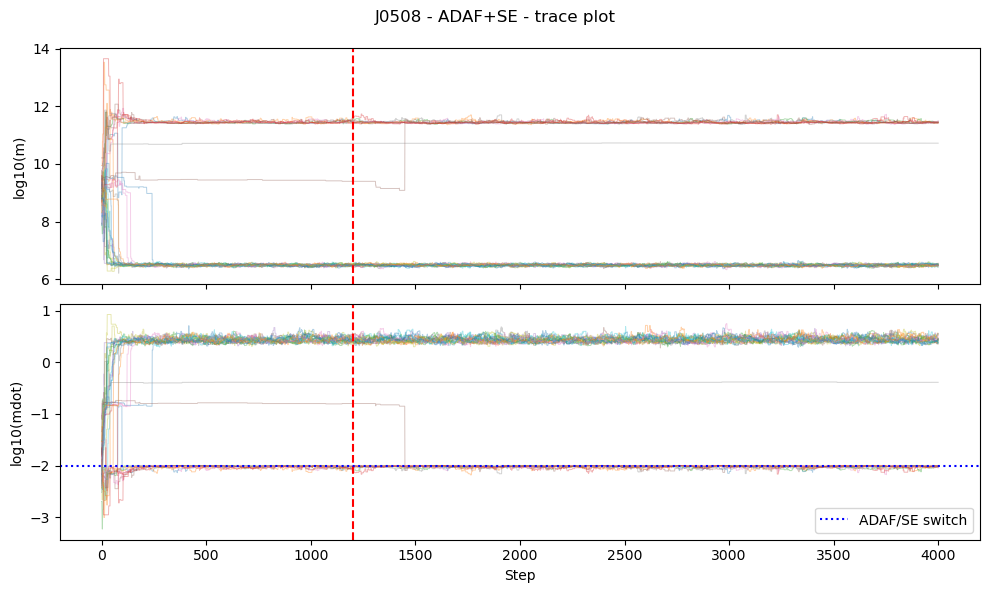

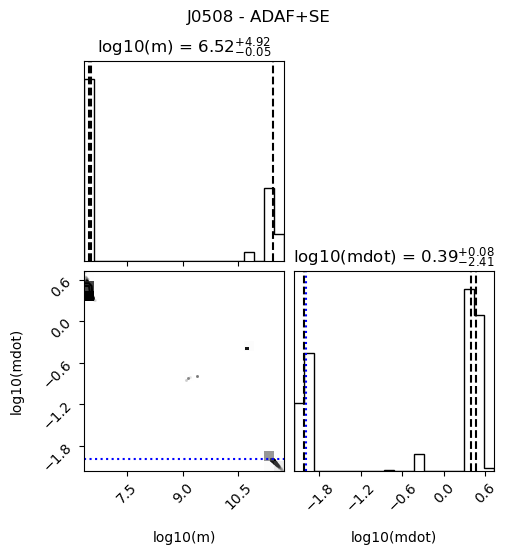

In [22]:
# ============================================================
# RUN COMPLETE FIT
# ============================================================

fit_results = (
    fit_blazar_with_unified_mcmc(
        CFG
    )
)